# 1. Load and validate the cleaned dataset

Load the prepared hERG data and check that canonical SMILES are present and unique and that the blocking labels are binary. This confirms the dataset is ready for scaffold analysis and splitting.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
requirements_path = project_root / "requirements.txt"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

%pip install -r "{requirements_path}" 

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json

from rdkit import Chem
from sklearn.model_selection import StratifiedGroupKFold
from src.evaluation import get_scaffold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt







Note: you may need to restart the kernel to use updated packages.


In [2]:
# Locate the project directory.
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

df_clf = pd.read_csv(
    project_root / "data" / "processed" / "herg_clean.csv"
)

# Check that cleaning has been completed.
assert df_clf["Canonical_smiles"].notna().all()
assert df_clf["Canonical_smiles"].is_unique
assert df_clf["Blocking_status"].isin([0, 1]).all()

df_clf["Blocking_status"] = df_clf["Blocking_status"].astype(int)

print("Number of molecules:", len(df_clf))

Number of molecules: 645


# 2. Examine the scaffold distribution

Assign each molecule a Bemis–Murcko scaffold and inspect the most common scaffold groups. This shows how many compounds share a structural core and motivates keeping related scaffolds together when splitting the data.

In [3]:

df_clf["scaffold"] = df_clf["Canonical_smiles"].apply(get_scaffold)

assert df_clf["scaffold"].notna().all(), "Invalid structures to inspect."

print("Number of groups:", df_clf["scaffold"].nunique())

# Inspect the largest groups.
display(df_clf["scaffold"].value_counts().head(10))


Number of groups: 439


[18:55:41] WARNING: not removing hydrogen atom without neighbors
[18:55:41] WARNING: not removing hydrogen atom without neighbors


scaffold
c1ccccc1                                              32
O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2ccccc2o1    15
c1ccc(Cc2ccccc2)cc1                                   12
c1ccc(-c2[nH]c3ccccc3c2[C@H]2CCC[NH2+]C2)cc1          10
c1ccc(-n2ccc3ccccc32)cc1                               8
O=C(NC1CCN(Cc2ccccc2)CC1)c1cc(=O)c2ccccc2o1            8
O=C1NCCN1CCN1CCC(c2cn(-c3ccccc3)c3ccccc23)CC1          7
O=C1NCCN1CC[NH+]1CCC(c2cn(-c3ccccc3)c3ccccc23)CC1      7
c1ccc(Cc2ccccn2)cc1                                    6
c1ccc2c(c1)Nc1ccccc1S2                                 6
Name: count, dtype: int64

### Interpreting the most common scaffolds

The table shows that the molecules are not all structurally unrelated: some share the same underlying molecular core.
The Bemis–Murcko method  keeps a molecule's ring systems and the chains that connect those rings, while removing most groups attached around the outside. Compounds with the same remaining framework are therefore placed in the same scaffold group, even if their attached side groups differ.

This pattern matters for modeling: if compounds with the same core were randomly placed in both training and test sets, the model could be evaluated on structures very similar to ones it had already seen. The scaffold-based split below keeps each group together, so the test set better measures how well the model handles compounds with scaffold frameworks absent from training. The counts also reveal that some scaffolds form larger groups than others, which can make a balanced split more challenging.

# 3. Create scaffold-aware data splits

Reserve a scaffold-disjoint test set for final evaluation, then divide the training set into five scaffold-aware cross-validation folds for model selection. Grouping by scaffold reduces the chance that closely related molecular cores appear in both fitting and validation data.

In [4]:
# Configure a five-fold cross-validation split.
# Keep compounds with the same scaffold in the same fold to avoid related structures
# appearing in both the training and test sets.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X=df_clf,
        y=df_clf["Blocking_status"],
        groups=df_clf["scaffold"]
    )
)
assert df_clf["scaffold"].notna().all(), "Invalid structures to inspect."

# Use the first split: one fold for testing and four for training
# The fixed random state makes the shuffled split reproducible.
# Label each molecule with its assigned partition.
df_clf["split"] = "train"
df_clf.loc[test_idx, "split"] = "test"

# Create separate datasets and reset their indexes for convenient downstream use.
train_df = df_clf.iloc[train_idx].copy().reset_index(drop=True)
test_df = df_clf.iloc[test_idx].copy().reset_index(drop=True)

In [5]:
# No group or identical structure should occur in both sets.
assert set(train_df["scaffold"]).isdisjoint(test_df["scaffold"])
assert set(train_df["Canonical_smiles"]).isdisjoint(test_df["Canonical_smiles"])

# Both sets must contain blockers and non-blockers.
assert train_df["Blocking_status"].nunique() == 2
assert test_df["Blocking_status"].nunique() == 2

# Summarize class counts and split sizes.
summary = pd.crosstab(
    df_clf["split"],
    df_clf["Blocking_status"]
).reindex(columns=[0, 1], fill_value=0)

summary.columns = ["Non-blockers", "Blockers"]
summary["Total"] = summary["Non-blockers"] + summary["Blockers"]
summary["Dataset (%)"] = 100 * summary["Total"] / len(df_clf)
summary["Blockers (%)"] = 100 * summary["Blockers"] / summary["Total"]

display(summary.round(1))
display(test_df.head())
display(train_df.head())

,Non-blockers,Blockers,Total,Dataset (%),Blockers (%)
split,,,,,
test,50,76,126,19.5,60.3
train,151,368,519,80.5,70.9


,Drug_ID,SMILES,Blocking_status,Canonical_smiles,scaffold,split
0,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,c1ccccc1,test
1,VANOXERINE HYDROCHLORIDE,Fc1ccc(C(OCCN2CCN(CCCc3ccccc3)CC2)c2ccc(F)cc2)cc1,1,Fc1ccc(C(OCCN2CCN(CCCc3ccccc3)CC2)c2ccc(F)cc2)cc1,c1ccc(CCCN2CCN(CCOC(c3ccccc3)c3ccccc3)CC2)cc1,test
2,DOFETILIDE,C[NH+](CCOc1ccc(NS(C)(=O)=O)cc1)CCc1ccc(NS(C)(...,1,C[NH+](CCOc1ccc(NS(C)(=O)=O)cc1)CCc1ccc(NS(C)(...,c1ccc(CC[NH2+]CCOc2ccccc2)cc1,test
3,BMCL20031829_15,CN(C)Cc1cc2cc(Cl)ccc2n1-c1ccc(F)cc1,1,CN(C)Cc1cc2cc(Cl)ccc2n1-c1ccc(F)cc1,c1ccc(-n2ccc3ccccc32)cc1,test
4,CLOFILIUM,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1,1,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1,c1ccccc1,test


,Drug_ID,SMILES,Blocking_status,Canonical_smiles,scaffold,split
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,c1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccccc3)CC2)cc1,train
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,c1ccc(CCC[NH+]2CC[NH+](CCOC(c3ccccc3)c3ccccc3)...,train
2,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,c1ccccc1.c1ccccc1.c1ccccc1,train
3,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccccc1)c1cc...,train
4,BENPERIDOL,O=C(CCCN1CCC(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F)cc1,1,O=C(CCCN1CCC(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F)cc1,O=C(CCCN1CCC(n2c(=O)[nH]c3ccccc32)CC1)c1ccccc1,train


In [6]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(
    cv.split(
        X=train_df,
        y=train_df["Blocking_status"],
        groups=train_df["scaffold"]
    )
)

train_df["cv_fold"] = -1
fold_summary = []

for fold, (fit_idx, valid_idx) in enumerate(cv_splits):
    fit_data = train_df.iloc[fit_idx]
    valid_data = train_df.iloc[valid_idx]

    # Check group separation.
    assert set(fit_data["scaffold"]).isdisjoint(valid_data["scaffold"])

    # Both classes must be present in training and validation.
    assert fit_data["Blocking_status"].nunique() == 2, (
        f"Only one class in training fold {fold}."
    )
    assert valid_data["Blocking_status"].nunique() == 2, (
        f"Only one class in validation fold {fold}."
    )

    # Record the fold where each molecule is used for validation.
    train_df.loc[valid_idx, "cv_fold"] = fold

    fold_summary.append({
        "Fold": fold,
        "Training molecules": len(fit_data),
        "Training blockers": int(fit_data["Blocking_status"].sum()),
        "Validation molecules": len(valid_data),
        "Validation blockers": int(valid_data["Blocking_status"].sum())
    })

assert train_df["cv_fold"].ge(0).all()

display(pd.DataFrame(fold_summary))

,Fold,Training molecules,Training blockers,Validation molecules,Validation blockers
0,0,409,294,110,74
1,1,412,295,107,73
2,2,418,293,101,75
3,3,416,294,103,74
4,4,421,296,98,72


In [7]:
# Map validation folds back to the full dataset.
fold_mapping = train_df.set_index("Canonical_smiles")["cv_fold"]

df_clf["cv_fold"] = (
    df_clf["Canonical_smiles"]
    .map(fold_mapping)
    .astype("Int64")
)

display(df_clf.head())

# Test molecules intentionally have no CV fold.
split_dir = project_root / "data" / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

df_clf.to_csv(
    split_dir / "herg_scaffold_split.csv",
    index=False
)


,Drug_ID,SMILES,Blocking_status,Canonical_smiles,scaffold,split,cv_fold
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,c1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccccc3)CC2)cc1,train,4
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,c1ccc(CCC[NH+]2CC[NH+](CCOC(c3ccccc3)c3ccccc3)...,train,2
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,c1ccccc1,test,<NA>
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,c1ccccc1.c1ccccc1.c1ccccc1,train,3
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccccc1)c1cc...,train,3


### Split results

The 645 molecules form 439 scaffold groups. The reproducible holdout split contains 519 training molecules (80.5%) and 126 test molecules (19.5%), with no scaffold shared between the sets. The split aims to preserve the blocker/non-blocker proportions, but the scaffold constraint means they are not identical: blockers make up 70.9% of training and 60.3% of test.

For model selection, the training set was further divided into five scaffold-aware cross-validation folds. Each fold serves once as validation while the other four are used for fitting, with scaffolds kept separate. The held-out test set remains untouched for final evaluation.



# 4. Generate and inspect molecular descriptors

Calculate 210 RDKit descriptors for each molecule in the training and test sets, keeping feature rows aligned with their labels. Check the matrix dimensions and identify missing descriptor values so they can be handled appropriately during model training.

In [8]:
from src.features import compute_descriptors

# Extract target labels.
y_train = train_df["Blocking_status"].to_numpy()
y_test = test_df["Blocking_status"].to_numpy()

# Calculate molecular features.
X_train_desc = compute_descriptors(train_df["Canonical_smiles"])
X_test_desc = compute_descriptors(test_df["Canonical_smiles"])


print("Training descriptors:", X_train_desc.shape)
print("Test descriptors:", X_test_desc.shape)

display(X_train_desc.head())
display(X_test_desc.head())

[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not removing hydrogen atom without neighbors
[18:55:46] WARNING: not r

Training descriptors: (519, 210)
Test descriptors: (126, 210)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,13.360182,13.360182,0.217816,-0.217816,0.418965,15.181818,444.554,415.322,444.232540,170,...,0,0,0,0,0,0,0,0,0,0
1,13.400224,13.400224,0.272972,-0.323611,0.483846,18.515152,452.589,418.317,452.262823,174,...,0,0,0,0,0,0,0,0,0,0
2,8.548611,8.548611,0.837475,-5.388889,0.032352,11.824324,1111.931,1000.043,1109.737779,428,...,0,0,0,0,0,0,0,0,12,0
3,13.504638,13.504638,0.098069,-0.448798,0.543063,22.085714,476.591,444.335,476.250796,182,...,0,0,0,0,0,0,0,0,0,0
4,12.948477,12.948477,0.037459,-0.325252,0.661510,15.892857,381.451,357.259,381.185255,146,...,0,0,0,0,0,0,0,0,0,0


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,10.625119,10.625119,0.174983,-0.343833,0.284606,11.086957,320.477,288.221,320.246378,130,...,0,0,0,0,0,0,0,0,4,0
1,13.394919,13.394919,0.279402,-0.342152,0.415758,15.242424,450.573,418.317,450.248270,174,...,0,0,0,0,0,0,0,0,0,0
2,11.221609,11.221609,0.500322,-3.282513,0.471730,12.931034,442.583,414.359,442.146489,160,...,0,2,0,0,0,0,0,0,0,0
3,13.170886,13.170886,0.229245,-0.229245,0.692104,11.476190,302.780,286.652,302.098604,108,...,0,0,0,0,0,0,0,0,0,0
4,5.948063,5.948063,0.837475,0.837475,0.284619,11.826087,338.987,301.691,338.260904,132,...,0,0,0,0,0,0,0,0,4,0


### Descriptor checks

Confirm that the feature matrices align with the target labels and share the same descriptor columns. Inspect missing values in the training descriptors; any imputation strategy should be fitted on training data only.

In [9]:
# Check that features and labels have matching lengths.
assert len(X_train_desc) == len(y_train)
assert len(X_test_desc) == len(y_test)

# Check that both datasets contain the same descriptor columns.
assert X_train_desc.columns.equals(X_test_desc.columns)

# Count missing values in each training descriptor.
missing_values = X_train_desc.isna().sum()

print(
    "Descriptors with missing training values:",
    (missing_values > 0).sum()
)

display(missing_values[missing_values > 0])

Descriptors with missing training values: 8


BCUT2D_MWHI       4
BCUT2D_MWLOW      4
BCUT2D_CHGHI      4
BCUT2D_CHGLO      4
BCUT2D_LOGPHI     4
BCUT2D_LOGPLOW    4
BCUT2D_MRHI       4
BCUT2D_MRLOW      4
dtype: int64

In [10]:
# Identify molecules with at least one missing descriptor.
missing_mask = X_train_desc.isna().any(axis=1)

print("Molecules affected:", missing_mask.sum())

display(
    train_df.loc[
        missing_mask,
        ["Canonical_smiles", "Blocking_status"]
    ]
)

Molecules affected: 4


,Canonical_smiles,Blocking_status
445,O=C(O)CN(CCN(CC(=O)O)CC(=O)O)CC(=O)O.[Cu+2],0
446,O=C(O)CN(CCN(CC(=O)O)CC(=O)O)CC(=O)O.[Mn+2],0
452,O=C(O)CCC(O)=C1S(=O)(=O)OCCOS1(=O)=O.[H-].[Na+],0
453,CC[C@@](O)(C(=O)O)c1cc2n(c(=O)c1CO)Cc1cc3ccccc...,0


### Visualize descriptor space with PCA

The imputer, scaler, and PCA are fitted on the training descriptors only; points are colored by the known blocking labels. 

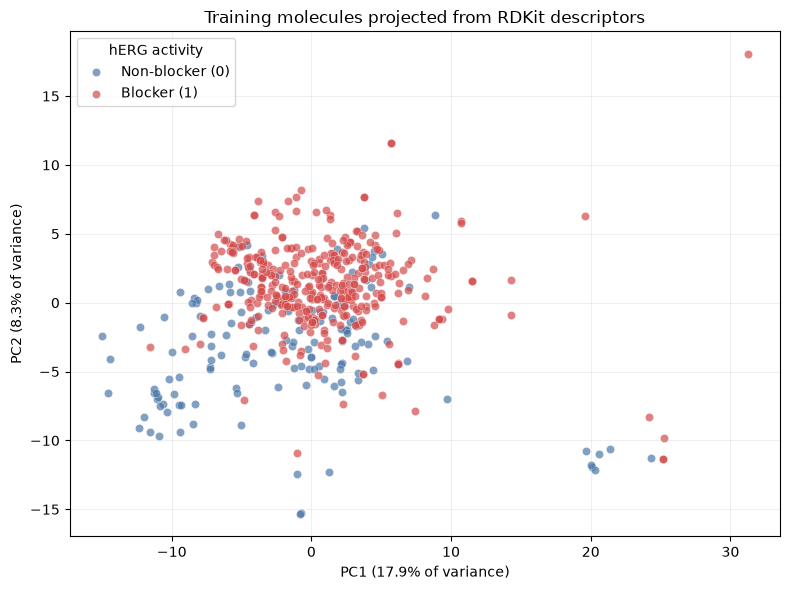

In [11]:
descriptor_pca = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2))
])

X_train_pca = descriptor_pca.fit_transform(X_train_desc)
explained_variance = descriptor_pca.named_steps["pca"].explained_variance_ratio_ * 100

plt.figure(figsize=(8, 6))
for label, label_name, color in [
    (0, "Non-blocker (0)", "#4C78A8"),
    (1, "Blocker (1)", "#D34A4A")
]:
    mask = y_train == label
    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        label=label_name,
        color=color,
        alpha=0.7,
        s=35,
        edgecolors="white",
        linewidths=0.3
    )

plt.xlabel(f"PC1 ({explained_variance[0]:.1f}% of variance)")
plt.ylabel(f"PC2 ({explained_variance[1]:.1f}% of variance)")
plt.title("Training molecules projected from RDKit descriptors")
plt.legend(title="hERG activity")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 5. Generate Morgan fingerprints

Create radius-2 Morgan fingerprints with 2,048 bits for the training and test molecules. Verify that fingerprints preserve molecule order and contain only binary values.

In [12]:
from src.features import compute_morgan

# Calculate fingerprints in the same molecule order as the descriptors.
X_train_morgan = compute_morgan(train_df["Canonical_smiles"])
X_test_morgan = compute_morgan(test_df["Canonical_smiles"])

print("Training fingerprints:", X_train_morgan.shape)
print("Test fingerprints:", X_test_morgan.shape)

display(X_train_morgan.head())

[18:55:48] WARNING: not removing hydrogen atom without neighbors
[18:55:48] WARNING: not removing hydrogen atom without neighbors


Training fingerprints: (519, 2048)
Test fingerprints: (126, 2048)


,0,1,2,3,4,5,6,7,8,9,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,0


### Fingerprint checks

In [13]:
# Check alignment with the descriptor matrices.
assert X_train_morgan.index.equals(X_train_desc.index)
assert X_test_morgan.index.equals(X_test_desc.index)

# Check that all fingerprint values are binary.
assert X_train_morgan.isin([0, 1]).all().all()
assert X_test_morgan.isin([0, 1]).all().all()

### Summary before model fitting

Before fitting the classification models, the cleaned hERG dataset was checked to ensure that canonical SMILES are present and unique and that `Blocking_status` contains only the binary labels 0 and 1. Molecules were divided into training and held-out test sets using a scaffold-aware split: the 519 training molecules and 126 test molecules do not share Bemis–Murcko scaffolds. The training set was further organized into five scaffold-aware cross-validation folds for model selection, leaving the test set aside for final evaluation.

Two molecular representations were then generated for both sets, preserving the molecule order and alignment with the target labels:

- **RDKit descriptors:** 210 numerical descriptors per molecule (519 × 210 for training; 126 × 210 for test).
- **Morgan fingerprints:** 2,048-bit fingerprints with radius 2 (519 × 2,048 for training; 126 × 2,048 for test).

The feature matrices were checked for matching dimensions and row alignment; the Morgan fingerprints were also verified to contain only binary values. The descriptor matrices contain missing values in 8 descriptor columns affecting 4 training molecules, so these values should be handled using a strategy fitted on the training data before model fitting.

# 6. Compare models and molecular representations with cross-validation

We evaluate Random Forest and SVC pipelines with both RDKit descriptors and Morgan fingerprints. All four configurations use the same five scaffold-aware folds and metrics, so their validation scores can be compared before looking at test-set performance.

### Random Forest with RDKit descriptors

The descriptor-based Random Forest is evaluated first. Its pipeline imputes missing descriptor values and removes constant features before fitting the classifier.

In [14]:
rf_desc = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("constant_features", VarianceThreshold(threshold=0)),

    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [15]:
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall"
}

rf_desc_scores = cross_validate(
    estimator=rf_desc,
    X=X_train_desc,
    y=y_train,
    cv=cv_splits,
    scoring=scoring,
    return_train_score=True
)

In [16]:

rows = []

for metric in scoring:
    train_scores = rf_desc_scores[f"train_{metric}"]
    validation_scores = rf_desc_scores[f"test_{metric}"]

    rows.append({
        "Metric": metric,
        "Train mean": train_scores.mean(),
        "Validation mean": validation_scores.mean(),
        "Validation std": validation_scores.std()
    })

rf_desc_summary = pd.DataFrame(rows)

display(rf_desc_summary.round(3))

,Metric,Train mean,Validation mean,Validation std
0,roc_auc,1.000,0.876,0.046
1,average_precision,1.000,0.930,0.035
2,f1,0.997,0.881,0.015
3,precision,0.995,0.851,0.029
4,recall,0.999,0.916,0.041


### Random Forest with Morgan fingerprints

The Morgan-based Random Forest uses the same classifier settings and cross-validation folds, allowing a direct comparison with the descriptor-based model.

In [17]:
rf_morgan = Pipeline([
    ("constant_features", VarianceThreshold(threshold=0)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_morgan_scores = cross_validate(
    estimator=rf_morgan,
    X=X_train_morgan,
    y=y_train,
    cv=cv_splits,
    scoring=scoring,
    return_train_score=True
)

metric_names = {
    "roc_auc": "ROC-AUC",
    "average_precision": "Average precision",
    "f1": "F1",
    "precision": "Precision",
    "recall": "Recall"
}

comparison_rows = []
for model_name, scores in [
    ("Random Forest + descriptors", rf_desc_scores),
    ("Random Forest + Morgan", rf_morgan_scores)
]:
    row = {"Model": model_name}
    for metric, label in metric_names.items():
        validation_scores = scores[f"test_{metric}"]
        row[f"{label} mean"] = validation_scores.mean()
        row[f"{label} std"] = validation_scores.std()
    comparison_rows.append(row)

model_cv_comparison = pd.DataFrame(comparison_rows).sort_values(
    "Average precision mean",
    ascending=False
).reset_index(drop=True)

display(model_cv_comparison.round(3))

,Model,ROC-AUC mean,ROC-AUC std,Average precision mean,Average precision std,F1 mean,F1 std,Precision mean,Precision std,Recall mean,Recall std
0,Random Forest + descriptors,0.876,0.046,0.930,0.035,0.881,0.015,0.851,0.029,0.916,0.041
1,Random Forest + Morgan,0.854,0.049,0.925,0.025,0.867,0.019,0.799,0.025,0.951,0.043


### Support vector classifier (SVC)

The SVC models are evaluated with both molecular representations using the same scaffold-aware folds and metrics.

#### SVC with RDKit descriptors

In [18]:


svc_desc = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("constant_features", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1,
        gamma="scale"
    ))
])

In [19]:
svc_desc_scores = cross_validate(
    svc_desc,
    X_train_desc,
    y_train,
    cv=cv_splits,
    scoring=scoring,
    return_train_score=True,
    error_score="raise"
)

#### SVC with Morgan fingerprints

In [20]:
svc_morgan = Pipeline([
    ("constant_features", VarianceThreshold()),
    ("model", SVC(
        kernel="rbf",
        C=1,
        gamma="scale"
    ))
]) 

In [21]:
svc_morgan_scores = cross_validate(
    svc_morgan,
    X_train_morgan,
    y_train,
    cv=cv_splits,
    scoring=scoring,
    return_train_score=True,
    error_score="raise"
)

In [22]:
comparison_rows = []

for model_name, scores in [
    ("RF + descriptors", rf_desc_scores),
    ("RF + Morgan", rf_morgan_scores),
    ("SVC + descriptors", svc_desc_scores),
    ("SVC + Morgan", svc_morgan_scores)
]:
    row = {"Model": model_name}

    for metric, label in metric_names.items():
        row[f"{label} mean"] = scores[f"test_{metric}"].mean()
        row[f"{label} std"] = scores[f"test_{metric}"].std()

    comparison_rows.append(row)

all_models_comparison = pd.DataFrame(comparison_rows)

display(all_models_comparison.round(3))

,Model,ROC-AUC mean,ROC-AUC std,Average precision mean,Average precision std,F1 mean,F1 std,Precision mean,Precision std,Recall mean,Recall std
0,RF + descriptors,0.876,0.046,0.930,0.035,0.881,0.015,0.851,0.029,0.916,0.041
1,RF + Morgan,0.854,0.049,0.925,0.025,0.867,0.019,0.799,0.025,0.951,0.043
2,SVC + descriptors,0.866,0.042,0.927,0.037,0.879,0.027,0.833,0.023,0.932,0.049
3,SVC + Morgan,0.853,0.049,0.924,0.031,0.883,0.017,0.826,0.024,0.949,0.031


# 7. Interpret the cross-validation results

The table summarizes performance across five scaffold-aware validation folds. Mean average precision (AP) is the primary ranking metric here because it evaluates how well the models identify blockers across score thresholds. Random Forest with RDKit descriptors has the highest mean AP (0.930 ± 0.035), followed closely by SVC with descriptors (0.927 ± 0.037), Random Forest with Morgan fingerprints (0.925 ± 0.025), and SVC with Morgan fingerprints (0.924 ± 0.031). The small gaps suggest that these configurations perform similarly in cross-validation.

The precision and recall columns show a practical trade-off. Higher recall means fewer blockers are missed, while higher precision means fewer non-blockers are incorrectly flagged as blockers. For example, Random Forest with Morgan fingerprints has higher mean recall (0.951) but lower mean precision (0.799) than Random Forest with descriptors (0.916 recall and 0.851 precision).

The mean is not the only result to consider: the standard deviation indicates how much performance changes across scaffold splits. Because the differences between models are smaller than, or comparable to, their fold-to-fold variability, the apparent ranking should not be treated as proof that one representation is universally better. AP is used for ranking models here; the final operating threshold should be selected separately according to whether avoiding missed blockers or reducing false alarms is more important.

# 8. Fit the selected model and evaluate the held-out test set

Choose a model using the cross-validation results, refit its pipeline on all training molecules, and evaluate it once on the test set. Hyperparameter tuning uses only the training molecules and the scaffold-aware folds; the held-out test set is used only for this final estimate.

The test metrics answer a different question from cross-validation: how well does the selected configuration generalize to previously unseen scaffolds? A lower test score than the cross-validation score can indicate a realistic scaffold generalization gap rather than a failed analysis. Since the test set is used once, its results should be reported as the final estimate and not used to choose another model.

In [23]:
param_grid_rf = {
    "model__max_depth": [None, 10],
    "model__min_samples_leaf": [1, 3],
    "model__max_features": ["sqrt", 0.5]
}

In [24]:

grid_rf_desc = GridSearchCV(
    estimator=rf_desc,
    param_grid=param_grid_rf,
    cv=cv_splits,
    scoring=scoring,
    refit="average_precision",
    return_train_score=True,
    error_score="raise"
)

grid_rf_desc.fit(X_train_desc, y_train)

print("Best parameters:", grid_rf_desc.best_params_)
print("Best CV average precision:", round(grid_rf_desc.best_score_, 3))

Best parameters: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3}
Best CV average precision: 0.934


In [25]:
best_idx = grid_rf_desc.best_index_
rows = []

for metric in scoring:
    rows.append({
        "Metric": metric,
        "Initial validation mean":
            rf_desc_scores[f"test_{metric}"].mean(),
        "Tuned validation mean":
            grid_rf_desc.cv_results_[f"mean_test_{metric}"][best_idx],
        "Tuned validation std":
            grid_rf_desc.cv_results_[f"std_test_{metric}"][best_idx]
    })

rf_desc_tuning_comparison = pd.DataFrame(rows)
display(rf_desc_tuning_comparison.round(3))

,Metric,Initial validation mean,Tuned validation mean,Tuned validation std
0,roc_auc,0.876,0.877,0.049
1,average_precision,0.930,0.934,0.030
2,f1,0.881,0.889,0.024
3,precision,0.851,0.849,0.036
4,recall,0.916,0.935,0.037


In [26]:
grid_rf_morgan = GridSearchCV(
    estimator=rf_morgan,
    param_grid=param_grid_rf,
    cv=cv_splits,
    scoring=scoring,
    refit="average_precision",
    return_train_score=True,
    error_score="raise",
    verbose=1
)

grid_rf_morgan.fit(X_train_morgan, y_train)

print("Best parameters:", grid_rf_morgan.best_params_)
print("Best mean validation average precision:", round(grid_rf_morgan.best_score_, 3))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3}
Best mean validation average precision: 0.928


In [27]:
best_idx = grid_rf_morgan.best_index_
rows = []

for metric in scoring:
    rows.append({
        "Metric": metric,
        "Initial validation mean":
            rf_morgan_scores[f"test_{metric}"].mean(),
        "Tuned validation mean":
            grid_rf_morgan.cv_results_[f"mean_test_{metric}"][best_idx],
        "Tuned validation std":
            grid_rf_morgan.cv_results_[f"std_test_{metric}"][best_idx]
    })

rf_morgan_tuning_comparison = pd.DataFrame(rows)
display(rf_morgan_tuning_comparison.round(3))

,Metric,Initial validation mean,Tuned validation mean,Tuned validation std
0,roc_auc,0.854,0.847,0.047
1,average_precision,0.925,0.928,0.024
2,f1,0.867,0.868,0.022
3,precision,0.799,0.796,0.024
4,recall,0.951,0.957,0.040


In [28]:
param_grid_svc = {
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.001, 0.01]
}

In [29]:
grid_svc_desc = GridSearchCV(
    estimator=svc_desc,
    param_grid=param_grid_svc,
    cv=cv_splits,
    scoring=scoring,
    refit="average_precision",
    return_train_score=True,
    error_score="raise",
    verbose=1
)

grid_svc_desc.fit(X_train_desc, y_train)

print("Best parameters:", grid_svc_desc.best_params_)
print("Best CV average precision:", round(grid_svc_desc.best_score_, 3))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'model__C': 10, 'model__gamma': 'scale'}
Best CV average precision: 0.938


In [30]:
grid_svc_morgan = GridSearchCV(
    estimator=svc_morgan,
    param_grid=param_grid_svc,
    cv=cv_splits,
    scoring=scoring,
    refit="average_precision",
    return_train_score=True,
    error_score="raise",
    verbose=1
)

grid_svc_morgan.fit(X_train_morgan, y_train)

print("Best parameters:", grid_svc_morgan.best_params_)
print("Best CV average precision:", round(grid_svc_morgan.best_score_, 3))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'model__C': 10, 'model__gamma': 'scale'}
Best CV average precision: 0.929


In [31]:
rows = []

for model_name, search in [
    ("RF + descriptors", grid_rf_desc),
    ("RF + Morgan", grid_rf_morgan),
    ("SVC + descriptors", grid_svc_desc),
    ("SVC + Morgan", grid_svc_morgan)
]:
    best_idx = search.best_index_
    row = {"Model": model_name}

    for metric in scoring:
        row[f"{metric} mean"] = (
            search.cv_results_[f"mean_test_{metric}"][best_idx]
        )
        row[f"{metric} std"] = (
            search.cv_results_[f"std_test_{metric}"][best_idx]
        )

    rows.append(row)

tuned_comparison = pd.DataFrame(rows).sort_values(
    "average_precision mean",
    ascending=False
).reset_index(drop=True)

display(tuned_comparison.round(3))

,Model,roc_auc mean,roc_auc std,average_precision mean,average_precision std,f1 mean,f1 std,precision mean,precision std,recall mean,recall std
0,SVC + descriptors,0.866,0.037,0.938,0.016,0.864,0.027,0.856,0.016,0.872,0.041
1,RF + descriptors,0.877,0.049,0.934,0.030,0.889,0.024,0.849,0.036,0.935,0.037
2,SVC + Morgan,0.860,0.049,0.929,0.027,0.881,0.021,0.842,0.015,0.924,0.040
3,RF + Morgan,0.847,0.047,0.928,0.024,0.868,0.022,0.796,0.024,0.957,0.040


In [32]:
# Associate each search with its corresponding test features.
candidates = {
    "RF + descriptors": (grid_rf_desc, X_test_desc),
    "RF + Morgan": (grid_rf_morgan, X_test_morgan),
    "SVC + descriptors": (grid_svc_desc, X_test_desc),
    "SVC + Morgan": (grid_svc_morgan, X_test_morgan)
}

best_model_name = tuned_comparison.loc[0, "Model"]
selected_search, X_selected_test = candidates[best_model_name]

# GridSearchCV already refitted this pipeline on all training molecules.
final_model = selected_search.best_estimator_

print("Selected model:", best_model_name)
print("Selected parameters:", selected_search.best_params_)

Selected model: SVC + descriptors
Selected parameters: {'model__C': 10, 'model__gamma': 'scale'}


## Cross-validation diagnostics

These confusion matrices use out-of-fold predictions from the training set. The held-out test set remains untouched during this diagnostic analysis.

For the positive class (blocker), the bottom-right cell is a correctly identified blocker (true positive), while the bottom-left cell is a missed blocker (false negative). The top-right cell is a non-blocker incorrectly flagged as a blocker (false positive). In a safety-oriented hERG screen, false negatives are especially important because they represent potentially blocking compounds that would not be prioritized for follow-up. These matrices therefore complement AP: AP evaluates ranking over many thresholds, whereas the confusion matrix describes performance at the default classification threshold.

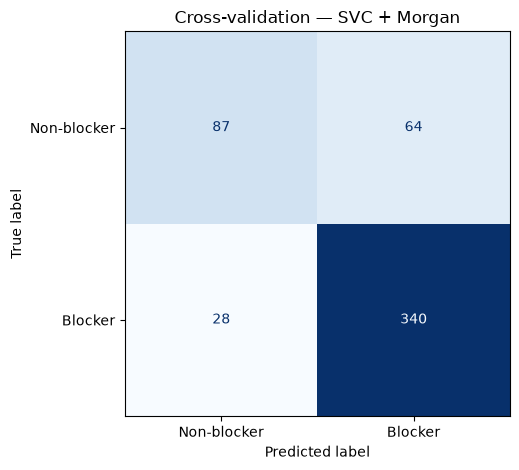

In [33]:

# Refit on each training fold and predict its validation fold.
svc_morgan_cv_pred = cross_val_predict(
    grid_svc_morgan.best_estimator_,
    X_train_morgan,
    y_train,
    cv=cv_splits
)

ConfusionMatrixDisplay.from_predictions(
    y_train,
    svc_morgan_cv_pred,
    labels=[0, 1],
    display_labels=["Non-blocker", "Blocker"],
    cmap="Blues",
    colorbar=False
)

plt.title("Cross-validation — SVC + Morgan")
plt.tight_layout()
plt.show()

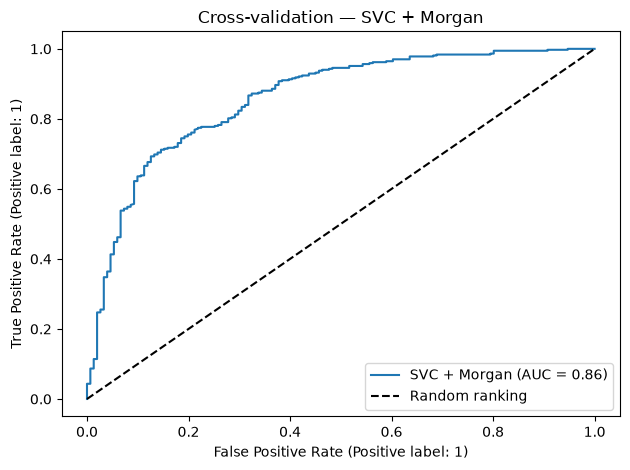

In [34]:
from sklearn.metrics import RocCurveDisplay

# Obtain validation scores instead of predicted classes.
svc_morgan_cv_scores = cross_val_predict(
    grid_svc_morgan.best_estimator_,
    X_train_morgan,
    y_train,
    cv=cv_splits,
    method="decision_function"
)

RocCurveDisplay.from_predictions(
    y_train,
    svc_morgan_cv_scores,
    name="SVC + Morgan"
)

plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.title("Cross-validation — SVC + Morgan")
plt.legend()
plt.tight_layout()
plt.show()

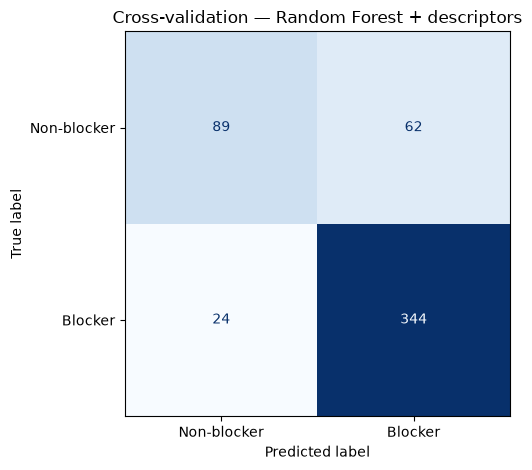

In [35]:
rf_desc_cv_pred = cross_val_predict(
    grid_rf_desc.best_estimator_,
    X_train_desc,
    y_train,
    cv=cv_splits,
    method="predict"
)

ConfusionMatrixDisplay.from_predictions(
    y_train,
    rf_desc_cv_pred,
    labels=[0, 1],
    display_labels=["Non-blocker", "Blocker"],
    cmap="Blues",
    colorbar=False
)

plt.title("Cross-validation — Random Forest + descriptors")
plt.tight_layout()
plt.show()

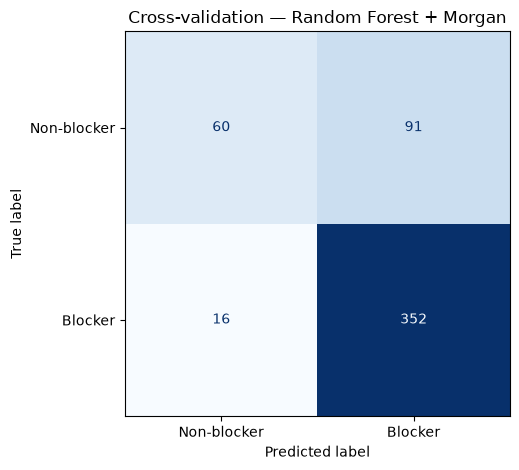

In [36]:
rf_morgan_cv_pred = cross_val_predict(
    grid_rf_morgan.best_estimator_,
    X_train_morgan,
    y_train,
    cv=cv_splits,
    method="predict"
)

ConfusionMatrixDisplay.from_predictions(
    y_train,
    rf_morgan_cv_pred,
    labels=[0, 1],
    display_labels=["Non-blocker", "Blocker"],
    cmap="Blues",
    colorbar=False
)

plt.title("Cross-validation — Random Forest + Morgan")
plt.tight_layout()
plt.show()

### Test of the selected model on the held-out test set.

Read the test metrics together rather than relying on accuracy alone. Accuracy can be misleading when the class proportions are unequal. Recall measures the fraction of blockers detected, precision measures how trustworthy the blocker predictions are, F1 balances precision and recall, and ROC-AUC summarizes ranking performance using both classes. The confusion matrix shows the actual numbers of false negatives and false positives for the threshold used by the classifier.

In [37]:
y_test_pred = final_model.predict(X_selected_test)

if best_model_name.startswith("SVC"):
    y_test_score = final_model.decision_function(X_selected_test)
else:
    y_test_score = final_model.predict_proba(X_selected_test)[:, 1]

In [38]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix
)

final_test_results = pd.DataFrame([{
    "Model": best_model_name,
    "ROC-AUC": roc_auc_score(y_test, y_test_score),
    "Average precision": average_precision_score(y_test, y_test_score),
    "F1": f1_score(y_test, y_test_pred, zero_division=0),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "Accuracy": accuracy_score(y_test, y_test_pred)
}])

display(final_test_results.round(3))

confusion = pd.DataFrame(
    confusion_matrix(y_test, y_test_pred, labels=[0, 1]),
    index=["True non-blocker", "True blocker"],
    columns=["Predicted non-blocker", "Predicted blocker"]
)

display(confusion)

,Model,ROC-AUC,Average precision,F1,Precision,Recall,Accuracy
0,SVC + descriptors,0.882,0.924,0.846,0.825,0.868,0.81


,Predicted non-blocker,Predicted blocker
True non-blocker,36,14
True blocker,10,66


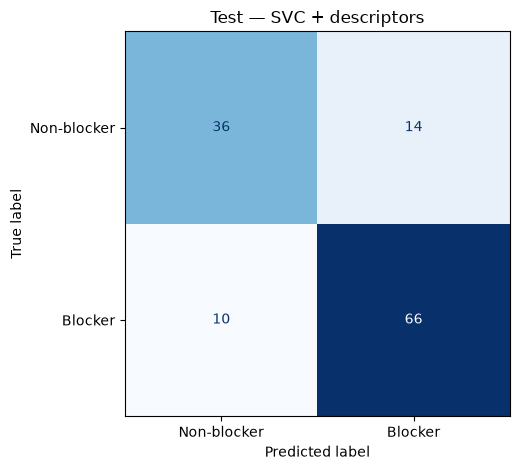

In [39]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=["Non-blocker", "Blocker"],
    cmap="Blues",
    colorbar=False
)

plt.title(f"Test — {best_model_name}")
plt.tight_layout()
plt.show()

# 9. Precision-recall curve on the held-out test set

The precision-recall curve is useful here because the blocker and non-blocker classes are not equally represented. The dashed line is the test-set blocker prevalence, which is the expected average precision of a random ranking.

A curve that remains above the dashed baseline indicates that the model ranks blockers better than random. Moving toward higher recall generally lowers precision: more blockers are found, but more non-blockers are also flagged. The area under this curve is summarized by average precision (AP), which is the ranking metric used for model selection. The curve also helps choose an operating threshold: for an early safety screen, a point with higher recall may be preferred to minimize missed blockers, whereas a costly experimental campaign may require higher precision. The selected threshold and its intended use should therefore be stated explicitly.

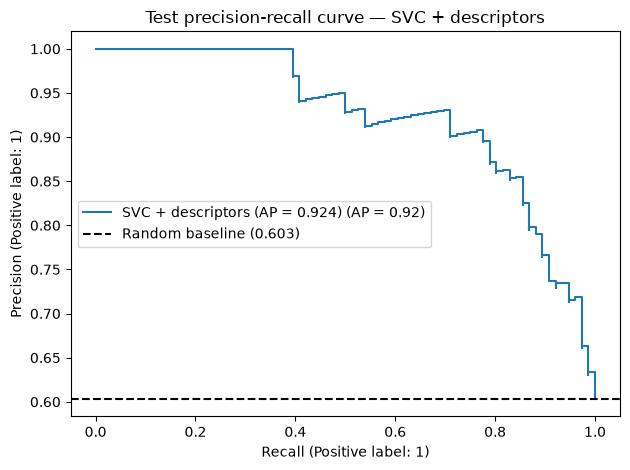

In [40]:
from sklearn.metrics import PrecisionRecallDisplay

test_blocker_rate = y_test.mean()
average_precision = average_precision_score(y_test, y_test_score)

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_score,
    name=f"{best_model_name} (AP = {average_precision:.3f})"
)
plt.axhline(
    test_blocker_rate,
    color="k",
    linestyle="--",
    label=f"Random baseline ({test_blocker_rate:.3f})"
)
plt.title(f"Test precision-recall curve — {best_model_name}")
plt.legend()
plt.tight_layout()


# 10. Save tuned and final test results

Save the cross-validation comparison, selected hyperparameters, final held-out test metrics, confusion matrix, and test predictions. The test set is only used after model selection.


In [41]:

results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

# Save the tuned cross-validation comparison for all four configurations.
tuned_comparison.to_csv(results_dir / "herg_tuned_cv_results.csv", index=False)

# Save the final test metrics for the model selected using validation only.
final_test_results.to_csv(results_dir / "herg_test_results.csv", index=False)

# Save the final confusion matrix with explicit class labels.
confusion.to_csv(results_dir / "herg_test_confusion_matrix.csv")

# Save the best hyperparameters for every tuned configuration.
searches = {
    "RF + descriptors": grid_rf_desc,
    "RF + Morgan": grid_rf_morgan,
    "SVC + descriptors": grid_svc_desc,
    "SVC + Morgan": grid_svc_morgan,
}
best_params = {name: search.best_params_ for name, search in searches.items()}
with (results_dir / "herg_best_params.json").open("w") as handle:
    json.dump(best_params, handle, indent=2)

# Save each held-out test prediction and score for later error analysis.
test_predictions = test_df[["Drug_ID", "Canonical_smiles", "Blocking_status"]].copy()
test_predictions["predicted_status"] = y_test_pred
test_predictions["prediction_score"] = y_test_score
test_predictions["model"] = best_model_name
test_predictions.to_csv(results_dir / "herg_test_predictions.csv", index=False)


